# Promoter Behavioral Localization in Baseline DNABERT-2

## Objective

Determine which sequence properties drive promoter-associated representations in baseline, non-fine-tuned DNABERT-2.

Using the Layer-5 promoter probe established in Notebook 1, this study will separate the effects of:

1. nucleotide composition,
2. short-range sequence order,
3. regional position,
4. promoter motif identity,
5. broader sequence context.

This notebook establishes a controlled clean-versus-corrupt behavioral target before component-level mechanistic interventions.

# Cell 1 — Install the DNABERT-2-compatible environment

In [1]:
!pip install -q \
    transformers==4.44.2 \
    tokenizers==0.19.1 \
    huggingface-hub==0.24.7 \
    datasets \
    joblib \
    scikit-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 59.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 83.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 417.5/417.5 kB 31.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.39.0 requires huggingface-hub<2.0,>=0.34.0, but you have huggingface-hub 0.24.7 which is incompatible.
peft 0.19.1 requires huggingface_hub>=0.25.0, but you have huggingface-hub 0.24.7 which is incompatible.
gradio 6.20.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.24.7 which is incompatible.


# Cell 2 — Verify environment versions

In [2]:
import torch
import transformers
import tokenizers
import huggingface_hub

print("Torch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("CUDA available:", torch.cuda.is_available())

Torch: 2.11.0+cu128
Transformers: 4.44.2
Tokenizers: 0.19.1
Hugging Face Hub: 0.24.7
CUDA available: True


# Cell 3 — Imports, reproducibility, and persistent storage

In [3]:
from pathlib import Path
from collections import Counter
import random
import joblib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import load_dataset, Dataset
from google.colab import drive

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/algoverse/dnabert"
)

BASELINE_DIR = (
    PROJECT_DIR / "outputs/promoter_baseline_pilot"
)

BEHAVIOR_DIR = (
    PROJECT_DIR / "outputs/promoter_behavioral_localization"
)

BASELINE_DIR.mkdir(parents=True, exist_ok=True)
BEHAVIOR_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", device)
print("Project directory:", PROJECT_DIR)
print("Baseline directory exists:", BASELINE_DIR.exists())
print("Behavior directory exists:", BEHAVIOR_DIR.exists())

Mounted at /content/drive
Device: cuda
Project directory: /content/drive/MyDrive/algoverse/dnabert
Baseline directory exists: True
Behavior directory exists: True


# Cell 4 — Load GUE prom_core_all and reproduce Notebook 1 subsets

In [4]:
DATASET_NAME = "leannmlindsey/GUE"
DATASET_CONFIG = "prom_core_all"

TRAIN_PER_CLASS = 1000
DEV_PER_CLASS = 400
TEST_PER_CLASS = 400

PROBE_PATH = BASELINE_DIR / "dnabert_layer5_probe.joblib"

print("Loading dataset...")

promoter_dataset = load_dataset(
    DATASET_NAME,
    name=DATASET_CONFIG,
)


def balanced_subset(dataset_split, per_class, seed):
    df = dataset_split.to_pandas()
    sampled_parts = []

    for label in sorted(df["label"].unique()):
        sampled = (
            df[df["label"] == label]
            .sample(
                n=per_class,
                random_state=seed,
                replace=False,
            )
        )

        sampled_parts.append(sampled)

    subset_df = (
        pd.concat(sampled_parts)
        .sample(frac=1, random_state=seed)
        .reset_index(drop=True)
    )

    return Dataset.from_pandas(
        subset_df,
        preserve_index=False,
    )


pilot_train = balanced_subset(
    promoter_dataset["train"],
    TRAIN_PER_CLASS,
    SEED,
)

pilot_dev = balanced_subset(
    promoter_dataset["dev"],
    DEV_PER_CLASS,
    SEED,
)

pilot_test = balanced_subset(
    promoter_dataset["test"],
    TEST_PER_CLASS,
    SEED,
)

print("\nPilot train:", len(pilot_train))
print("Pilot dev:", len(pilot_dev))
print("Pilot test:", len(pilot_test))

print("\nTrain labels:", Counter(pilot_train["label"]))
print("Dev labels:", Counter(pilot_dev["label"]))
print("Test labels:", Counter(pilot_test["label"]))

print("\nSaved Layer-5 probe exists:", PROBE_PATH.exists())

if PROBE_PATH.exists():
    layer5_probe = joblib.load(PROBE_PATH)
    print("Layer-5 probe loaded successfully.")
else:
    print(
        "Layer-5 probe is not yet present in Drive; "
        "we will recreate and save it in this notebook."
    )

Loading dataset...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

train.csv: 0.00B [00:00, ?B/s]

test.csv: 0.00B [00:00, ?B/s]

dev.csv: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/47356 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5920 [00:00<?, ? examples/s]

Generating dev split:   0%|          | 0/5920 [00:00<?, ? examples/s]


Pilot train: 2000
Pilot dev: 800
Pilot test: 800

Train labels: Counter({1: 1000, 0: 1000})
Dev labels: Counter({1: 400, 0: 400})
Test labels: Counter({1: 400, 0: 400})

Saved Layer-5 probe exists: True
Layer-5 probe loaded successfully.


# Cell 5 — Load baseline DNABERT-2 and capture Layer 5

In [5]:
import gc
import torch

from transformers import AutoTokenizer, AutoModel
from transformers.models.bert.configuration_bert import BertConfig

MODEL_NAME = "quietflamingo/dnabert2-no-flashattention"
LAYER_INDEX = 4  # Zero-based index: Layer 5

# Remove objects left by any failed load.
for variable_name in ["backbone", "config", "tokenizer"]:
    if variable_name in globals():
        del globals()[variable_name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# The custom ALiBi implementation must be constructed on CPU.
torch.set_default_device("cpu")

print("CUDA available:", torch.cuda.is_available())
print("Loading tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True,
)

print("Loading standard BertConfig...")

config = BertConfig.from_pretrained(MODEL_NAME)

config.pad_token_id = tokenizer.pad_token_id
config.output_hidden_states = False
config.return_dict = False

print("Tokenizer pad token ID:", tokenizer.pad_token_id)
print("Config pad token ID:", config.pad_token_id)
print("Constructing model on CPU...")

backbone = AutoModel.from_pretrained(
    MODEL_NAME,
    config=config,
    trust_remote_code=True,
    low_cpu_mem_usage=False,
    device_map=None,
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Moving model to:", device)

backbone = backbone.to(device)
backbone.eval()

# Capture only Layer 5 activations.
captured_layer5 = {}

def layer5_hook(module, inputs, output):
    hidden = output[0] if isinstance(output, tuple) else output
    captured_layer5["hidden"] = hidden.detach()

layer5_hook_handle = (
    backbone.encoder.layer[LAYER_INDEX]
    .register_forward_hook(layer5_hook)
)

print("\nModel loaded successfully.")
print("Model class:", backbone.__class__.__name__)
print("Hidden size:", backbone.config.hidden_size)
print("Selected layer:", LAYER_INDEX + 1)
print("Model device:", next(backbone.parameters()).device)

CUDA available: True
Loading tokenizer...


tokenizer_config.json:   0%|          | 0.00/158 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Loading standard BertConfig...


/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


...

bert_padding.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/quietflamingo/dnabert2-no-flashattention:
- bert_padding.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
A new version of the following files was downloaded from https://huggingface.co/quietflamingo/dnabert2-no-flashattention:
- bert_layers.py
- bert_padding.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


pytorch_model.bin:   0%|          | 0.00/468M [00:00<?, ?B/s]

/root/.cache/huggingface/modules/transformers_modules/quietflamingo/dnabert2-no-flashattention/813031b2bf86d9e960a027e2734c908009f31601/bert_layers.py:123: UserWarning: Unable to import Triton; defaulting MosaicBERT attention implementation to pytorch (this will reduce throughput when using this model).
  warnings.warn(
Some weights of BertModel were not initialized from the model checkpoint at quietflamingo/dnabert2-no-flashattention and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Moving model to: cuda

Model loaded successfully.
Model class: BertModel
Hidden size: 768
Selected layer: 5
Model device: cuda:0


# Cell 6 — Extract content-token mean-pooled Layer-5 representations

In [6]:
from torch.utils.data import DataLoader
from tqdm.auto import tqdm


def split_and_content_mean_pool(flat_hidden, token_counts):
    pooled_sequences = []
    start = 0

    for count in token_counts:
        end = start + count
        sequence_hidden = flat_hidden[start:end]

        # Exclude [CLS] and [SEP].
        content_hidden = sequence_hidden[1:-1]

        if content_hidden.shape[0] == 0:
            raise ValueError(
                "Sequence has no content tokens after removing special tokens."
            )

        pooled_sequences.append(
            content_hidden.mean(dim=0)
        )

        start = end

    return torch.stack(pooled_sequences)


def extract_layer5_representations(
    dataset_split,
    batch_size=32,
):
    sequences = dataset_split["sequence"]
    labels = np.asarray(dataset_split["label"])

    dataloader = DataLoader(
        sequences,
        batch_size=batch_size,
        shuffle=False,
    )

    representation_batches = []

    for sequence_batch in tqdm(
        dataloader,
        desc="Extracting Layer-5 representations",
    ):
        encoded = tokenizer(
            list(sequence_batch),
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=128,
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        token_counts = (
            encoded["attention_mask"]
            .sum(dim=1)
            .tolist()
        )

        captured_layer5.clear()

        with torch.no_grad():
            _ = backbone(
                **encoded,
                return_dict=False,
            )

        if "hidden" not in captured_layer5:
            raise RuntimeError(
                "Layer-5 hook did not capture activations."
            )

        pooled = split_and_content_mean_pool(
            captured_layer5["hidden"],
            token_counts,
        )

        representation_batches.append(
            pooled.cpu()
        )

    representations = (
        torch.cat(representation_batches, dim=0)
        .numpy()
    )

    return representations, labels


# Smoke test first.
smoke_subset = pilot_train.select(range(32))

smoke_representations, smoke_labels = (
    extract_layer5_representations(
        smoke_subset,
        batch_size=16,
    )
)

print("Representations:", smoke_representations.shape)
print("Labels:", smoke_labels.shape)

Extracting Layer-5 representations:   0%|          | 0/2 [00:00<?, ?it/s]

Representations: (32, 768)
Labels: (32,)


# Cell 7 — Extract pilot representations, train the Layer-5 probe, and save it

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
)

print("Extracting pilot train representations...")

layer5_train_representations, layer5_train_labels = (
    extract_layer5_representations(
        pilot_train,
        batch_size=32,
    )
)

print("Extracting pilot dev representations...")

layer5_dev_representations, layer5_dev_labels = (
    extract_layer5_representations(
        pilot_dev,
        batch_size=32,
    )
)

print("Extracting pilot test representations...")

layer5_test_representations, layer5_test_labels = (
    extract_layer5_representations(
        pilot_test,
        batch_size=32,
    )
)

layer5_probe = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=3000,
        random_state=SEED,
        solver="liblinear",
    ),
)

layer5_probe.fit(
    layer5_train_representations,
    layer5_train_labels,
)

dev_predictions = layer5_probe.predict(
    layer5_dev_representations
)

dev_probabilities = layer5_probe.predict_proba(
    layer5_dev_representations
)[:, 1]

test_predictions = layer5_probe.predict(
    layer5_test_representations
)

test_probabilities = layer5_probe.predict_proba(
    layer5_test_representations
)[:, 1]

recreated_probe_results = pd.DataFrame([
    {
        "split": "dev",
        "balanced_accuracy": balanced_accuracy_score(
            layer5_dev_labels,
            dev_predictions,
        ),
        "roc_auc": roc_auc_score(
            layer5_dev_labels,
            dev_probabilities,
        ),
    },
    {
        "split": "test",
        "balanced_accuracy": balanced_accuracy_score(
            layer5_test_labels,
            test_predictions,
        ),
        "roc_auc": roc_auc_score(
            layer5_test_labels,
            test_probabilities,
        ),
    },
])

display(recreated_probe_results)

joblib.dump(
    layer5_probe,
    PROBE_PATH,
)

np.save(
    BASELINE_DIR / "layer5_train_representations.npy",
    layer5_train_representations,
)

np.save(
    BASELINE_DIR / "layer5_dev_representations.npy",
    layer5_dev_representations,
)

np.save(
    BASELINE_DIR / "layer5_test_representations.npy",
    layer5_test_representations,
)

np.save(
    BASELINE_DIR / "train_labels.npy",
    layer5_train_labels,
)

np.save(
    BASELINE_DIR / "dev_labels.npy",
    layer5_dev_labels,
)

np.save(
    BASELINE_DIR / "test_labels.npy",
    layer5_test_labels,
)

recreated_probe_results.to_csv(
    BASELINE_DIR / "recreated_layer5_probe_results.csv",
    index=False,
)

print("\nProbe saved to:")
print(PROBE_PATH)

print("\nProbe exists:", PROBE_PATH.exists())

Extracting pilot train representations...


Extracting Layer-5 representations:   0%|          | 0/63 [00:00<?, ?it/s]

Extracting pilot dev representations...


Extracting Layer-5 representations:   0%|          | 0/25 [00:00<?, ?it/s]

Extracting pilot test representations...


Extracting Layer-5 representations:   0%|          | 0/25 [00:00<?, ?it/s]

,split,balanced_accuracy,roc_auc
0,dev,0.70125,0.793000
1,test,0.73500,0.810638



Probe saved to:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_baseline_pilot/dnabert_layer5_probe.joblib

Probe exists: True


# Cell 8 — Measure clean Layer-5 promoter scores

In [8]:
def score_sequences_with_layer5_probe(
    sequences,
    batch_size=32,
):
    """
    Extract Layer-5 representations and return promoter probabilities.
    """
    temporary_dataset = Dataset.from_dict({
        "sequence": list(sequences),
        "label": [0] * len(sequences),
    })

    representations, _ = extract_layer5_representations(
        temporary_dataset,
        batch_size=batch_size,
    )

    promoter_probabilities = layer5_probe.predict_proba(
        representations
    )[:, 1]

    promoter_logits = layer5_probe.decision_function(
        representations
    )

    return representations, promoter_probabilities, promoter_logits


clean_test_sequences = pilot_test["sequence"]
clean_test_labels = np.asarray(pilot_test["label"])

(
    clean_test_representations,
    clean_test_probabilities,
    clean_test_logits,
) = score_sequences_with_layer5_probe(
    clean_test_sequences,
    batch_size=32,
)

clean_score_df = pd.DataFrame({
    "sequence": clean_test_sequences,
    "label": clean_test_labels,
    "promoter_probability": clean_test_probabilities,
    "promoter_logit": clean_test_logits,
})

clean_score_summary = (
    clean_score_df
    .groupby("label")[
        ["promoter_probability", "promoter_logit"]
    ]
    .agg(["mean", "std", "median"])
)

display(clean_score_summary)

print(
    "\nClean test balanced accuracy:",
    balanced_accuracy_score(
        clean_test_labels,
        clean_test_probabilities >= 0.5,
    ),
)

print(
    "Clean test ROC-AUC:",
    roc_auc_score(
        clean_test_labels,
        clean_test_probabilities,
    ),
)

Extracting Layer-5 representations:   0%|          | 0/25 [00:00<?, ?it/s]

promoter_probability                     promoter_logit            \
                      mean       std    median           mean       std   
label                                                                     
0                 0.275969  0.368166  0.031646      -3.046712  4.877646   
1                 0.723883  0.373312  0.969179       3.826984  6.468729   

                 
         median  
label            
0     -3.420993  
1      3.448689


Clean test balanced accuracy: 0.7350000000000001
Clean test ROC-AUC: 0.8106375000000001


# Cell 9 — Test whether promoter evidence survives destruction of sequence order

In [9]:
def mononucleotide_shuffle(sequence, seed):
    """
    Shuffle all nucleotides while preserving:
    - sequence length
    - exact A/C/G/T counts

    This destroys local order, motifs, and positional structure.
    """
    rng = np.random.default_rng(seed)
    bases = np.array(list(sequence))
    rng.shuffle(bases)
    return "".join(bases.tolist())


# Use only true promoters for the initial paired corruption test.
promoter_test_df = clean_score_df[
    clean_score_df["label"] == 1
].reset_index(drop=True)

promoter_sequences = promoter_test_df["sequence"].tolist()
promoter_clean_logits = promoter_test_df["promoter_logit"].to_numpy()
promoter_clean_probabilities = (
    promoter_test_df["promoter_probability"].to_numpy()
)

shuffled_promoter_sequences = [
    mononucleotide_shuffle(
        sequence,
        seed=SEED + sequence_index,
    )
    for sequence_index, sequence in enumerate(promoter_sequences)
]

# Validate exact composition preservation.
for clean_sequence, shuffled_sequence in zip(
    promoter_sequences,
    shuffled_promoter_sequences,
):
    assert len(clean_sequence) == len(shuffled_sequence)
    assert Counter(clean_sequence) == Counter(shuffled_sequence)

(
    shuffled_representations,
    shuffled_probabilities,
    shuffled_logits,
) = score_sequences_with_layer5_probe(
    shuffled_promoter_sequences,
    batch_size=32,
)

full_shuffle_results = pd.DataFrame({
    "sequence_index": np.arange(len(promoter_sequences)),
    "clean_logit": promoter_clean_logits,
    "shuffled_logit": shuffled_logits,
    "logit_drop": promoter_clean_logits - shuffled_logits,
    "clean_probability": promoter_clean_probabilities,
    "shuffled_probability": shuffled_probabilities,
    "probability_drop": (
        promoter_clean_probabilities - shuffled_probabilities
    ),
})

display(full_shuffle_results.describe())

print(
    "\nMean paired logit drop:",
    full_shuffle_results["logit_drop"].mean(),
)

print(
    "Median paired logit drop:",
    full_shuffle_results["logit_drop"].median(),
)

print(
    "Fraction of promoters with reduced score:",
    np.mean(full_shuffle_results["logit_drop"] > 0),
)

Extracting Layer-5 representations:   0%|          | 0/13 [00:00<?, ?it/s]

,sequence_index,clean_logit,shuffled_logit,logit_drop,clean_probability,shuffled_probability,probability_drop
count,400.000000,400.000000,400.000000,400.000000,400.000000,4.000000e+02,400.000000
mean,199.500000,3.826984,-0.943707,4.770691,0.723883,4.276148e-01,0.296268
std,115.614301,6.468729,6.013678,6.744404,0.373312,4.271579e-01,0.498421
min,0.000000,-12.932936,-18.228319,-15.411897,0.000002,1.212109e-08,-0.992998
25%,99.750000,-0.290591,-4.959573,0.231703,0.427865,6.967380e-03,0.000003
50%,199.500000,3.448689,-1.162966,4.722956,0.969179,2.381288e-01,0.158161
75%,299.250000,6.785130,3.109732,9.138824,0.998871,9.572561e-01,0.808352
max,399.000000,34.296556,28.589196,23.752010,1.000000,1.000000e+00,0.999908



Mean paired logit drop: 4.770690676273524
Median paired logit drop: 4.7229556654290645
Fraction of promoters with reduced score: 0.755


# Cell 10 — Repeat full shuffling to estimate corruption variability

In [10]:
N_SHUFFLE_REPEATS = 10

repeated_shuffled_sequences = []
repeated_sequence_indices = []
repeated_shuffle_ids = []

for shuffle_id in range(N_SHUFFLE_REPEATS):
    for sequence_index, sequence in enumerate(promoter_sequences):
        shuffled_sequence = mononucleotide_shuffle(
            sequence,
            seed=SEED
            + shuffle_id * len(promoter_sequences)
            + sequence_index,
        )

        repeated_shuffled_sequences.append(shuffled_sequence)
        repeated_sequence_indices.append(sequence_index)
        repeated_shuffle_ids.append(shuffle_id)

(
    repeated_shuffle_representations,
    repeated_shuffle_probabilities,
    repeated_shuffle_logits,
) = score_sequences_with_layer5_probe(
    repeated_shuffled_sequences,
    batch_size=32,
)

repeated_shuffle_results = pd.DataFrame({
    "sequence_index": repeated_sequence_indices,
    "shuffle_id": repeated_shuffle_ids,
    "shuffled_logit": repeated_shuffle_logits,
    "shuffled_probability": repeated_shuffle_probabilities,
})

# Add the corresponding clean values.
clean_logit_lookup = dict(
    enumerate(promoter_clean_logits)
)

clean_probability_lookup = dict(
    enumerate(promoter_clean_probabilities)
)

repeated_shuffle_results["clean_logit"] = (
    repeated_shuffle_results["sequence_index"]
    .map(clean_logit_lookup)
)

repeated_shuffle_results["clean_probability"] = (
    repeated_shuffle_results["sequence_index"]
    .map(clean_probability_lookup)
)

repeated_shuffle_results["logit_drop"] = (
    repeated_shuffle_results["clean_logit"]
    - repeated_shuffle_results["shuffled_logit"]
)

repeated_shuffle_results["probability_drop"] = (
    repeated_shuffle_results["clean_probability"]
    - repeated_shuffle_results["shuffled_probability"]
)

# Average the repeated corruption outcomes for each promoter.
per_promoter_shuffle_summary = (
    repeated_shuffle_results
    .groupby("sequence_index")
    .agg(
        clean_logit=("clean_logit", "first"),
        mean_shuffled_logit=("shuffled_logit", "mean"),
        std_shuffled_logit=("shuffled_logit", "std"),
        mean_logit_drop=("logit_drop", "mean"),
        clean_probability=("clean_probability", "first"),
        mean_shuffled_probability=("shuffled_probability", "mean"),
        mean_probability_drop=("probability_drop", "mean"),
    )
    .reset_index()
)

display(per_promoter_shuffle_summary.describe())

print(
    "\nMean repeated-shuffle logit drop:",
    per_promoter_shuffle_summary["mean_logit_drop"].mean(),
)

print(
    "Median repeated-shuffle logit drop:",
    per_promoter_shuffle_summary["mean_logit_drop"].median(),
)

print(
    "Fraction with positive mean drop:",
    np.mean(
        per_promoter_shuffle_summary["mean_logit_drop"] > 0
    ),
)

print(
    "Mean shuffled promoter probability:",
    per_promoter_shuffle_summary[
        "mean_shuffled_probability"
    ].mean(),
)

# Save the robust results.
repeated_shuffle_results.to_csv(
    BEHAVIOR_DIR / "full_shuffle_all_repeats.csv",
    index=False,
)

per_promoter_shuffle_summary.to_csv(
    BEHAVIOR_DIR / "full_shuffle_per_promoter_summary.csv",
    index=False,
)

print("\nResults saved to:", BEHAVIOR_DIR)

Extracting Layer-5 representations:   0%|          | 0/125 [00:00<?, ?it/s]

,sequence_index,clean_logit,mean_shuffled_logit,std_shuffled_logit,mean_logit_drop,clean_probability,mean_shuffled_probability,mean_probability_drop
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000
mean,199.500000,3.826984,-0.879508,4.280557,4.706492,0.723883,0.421480,0.302402
std,115.614301,6.468729,4.454488,1.038226,5.401942,0.373312,0.289781,0.379791
min,0.000000,-12.932936,-8.191584,1.655630,-10.567218,0.000002,0.002273,-0.658943
25%,99.750000,-0.290591,-4.330862,3.521544,1.139926,0.427865,0.182891,0.015385
50%,199.500000,3.448689,-1.717128,4.259198,4.809638,0.969179,0.335189,0.303088
75%,299.250000,6.785130,1.732344,4.919049,8.134291,0.998871,0.644742,0.652099
max,399.000000,34.296556,17.523758,7.920528,25.642141,1.000000,0.999996,0.996533



Mean repeated-shuffle logit drop: 4.706492095632609
Median repeated-shuffle logit drop: 4.8096380313880225
Fraction with positive mean drop: 0.81
Mean shuffled promoter probability: 0.4214803879335001

Results saved to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_behavioral_localization


# Cell 11 — Localize order-sensitive regions using regional shuffling

In [11]:
WINDOW_SIZE = 10
N_REGIONAL_REPEATS = 5

sequence_length_counts = Counter(
    len(sequence) for sequence in promoter_sequences
)

print("Promoter sequence lengths:", sequence_length_counts)

if len(sequence_length_counts) != 1:
    raise ValueError(
        "Regional analysis currently expects equal-length sequences."
    )

SEQUENCE_LENGTH = next(iter(sequence_length_counts))

window_starts = list(
    range(0, SEQUENCE_LENGTH, WINDOW_SIZE)
)

regional_corrupted_sequences = []
regional_metadata = []


def shuffle_sequence_region(
    sequence,
    start,
    end,
    seed,
):
    """
    Shuffle only sequence[start:end].

    Preserves:
    - total sequence composition,
    - composition inside the selected region,
    - all nucleotides outside the selected region.
    """
    rng = np.random.default_rng(seed)

    region = np.array(list(sequence[start:end]))
    rng.shuffle(region)

    return (
        sequence[:start]
        + "".join(region.tolist())
        + sequence[end:]
    )


for repeat_id in range(N_REGIONAL_REPEATS):
    for window_start in window_starts:
        window_end = min(
            window_start + WINDOW_SIZE,
            SEQUENCE_LENGTH,
        )

        for sequence_index, sequence in enumerate(
            promoter_sequences
        ):
            corruption_seed = (
                SEED
                + repeat_id * 100_000
                + window_start * 1_000
                + sequence_index
            )

            corrupted_sequence = shuffle_sequence_region(
                sequence=sequence,
                start=window_start,
                end=window_end,
                seed=corruption_seed,
            )

            # Validate the controlled corruption.
            assert len(corrupted_sequence) == len(sequence)
            assert Counter(corrupted_sequence) == Counter(sequence)

            assert (
                corrupted_sequence[:window_start]
                == sequence[:window_start]
            )

            assert (
                corrupted_sequence[window_end:]
                == sequence[window_end:]
            )

            regional_corrupted_sequences.append(
                corrupted_sequence
            )

            regional_metadata.append({
                "sequence_index": sequence_index,
                "repeat_id": repeat_id,
                "window_start": window_start,
                "window_end": window_end,
            })


print(
    "Regional corrupted sequences:",
    len(regional_corrupted_sequences),
)

(
    regional_representations,
    regional_probabilities,
    regional_logits,
) = score_sequences_with_layer5_probe(
    regional_corrupted_sequences,
    batch_size=32,
)

regional_results = pd.DataFrame(regional_metadata)

regional_results["corrupted_logit"] = regional_logits
regional_results["corrupted_probability"] = (
    regional_probabilities
)

regional_results["clean_logit"] = (
    regional_results["sequence_index"]
    .map(clean_logit_lookup)
)

regional_results["clean_probability"] = (
    regional_results["sequence_index"]
    .map(clean_probability_lookup)
)

regional_results["logit_drop"] = (
    regional_results["clean_logit"]
    - regional_results["corrupted_logit"]
)

regional_results["probability_drop"] = (
    regional_results["clean_probability"]
    - regional_results["corrupted_probability"]
)

regional_window_summary = (
    regional_results
    .groupby(["window_start", "window_end"])
    .agg(
        mean_logit_drop=("logit_drop", "mean"),
        median_logit_drop=("logit_drop", "median"),
        std_logit_drop=("logit_drop", "std"),
        mean_probability_drop=("probability_drop", "mean"),
        fraction_positive=("logit_drop", lambda x: np.mean(x > 0)),
    )
    .reset_index()
)

display(
    regional_window_summary.sort_values(
        "mean_logit_drop",
        ascending=False,
    )
)

regional_results.to_csv(
    BEHAVIOR_DIR / "regional_shuffle_all_results.csv",
    index=False,
)

regional_window_summary.to_csv(
    BEHAVIOR_DIR / "regional_shuffle_window_summary.csv",
    index=False,
)

print("\nRegional results saved.")

Promoter sequence lengths: Counter({70: 400})
Regional corrupted sequences: 14000


Extracting Layer-5 representations:   0%|          | 0/438 [00:00<?, ?it/s]

,window_start,window_end,mean_logit_drop,median_logit_drop,std_logit_drop,mean_probability_drop,fraction_positive
4,40,50,0.916160,0.882787,3.454472,0.058067,0.6080
3,30,40,0.880403,0.830285,3.490110,0.054880,0.6115
1,10,20,0.879120,0.773253,3.358117,0.062532,0.5910
0,0,10,0.812366,0.683197,3.159392,0.040786,0.5965
6,60,70,0.775747,0.806658,3.575907,0.048350,0.5970
2,20,30,0.760134,0.734406,3.442291,0.042246,0.5945
5,50,60,0.740362,0.630726,3.362372,0.048290,0.5860



Regional results saved.


# Cell 12 — Bootstrap uncertainty for each regional-shuffle effect

,window_start,window_end,mean_logit_drop,ci_2.5,ci_97.5,standard_error,window_label
0,0,10,0.812366,0.573915,1.051012,0.124931,0–10
1,10,20,0.879120,0.605852,1.141355,0.133524,10–20
2,20,30,0.760134,0.484850,1.015562,0.138344,20–30
3,30,40,0.880403,0.607452,1.154906,0.138467,30–40
4,40,50,0.916160,0.652520,1.182768,0.135381,40–50
5,50,60,0.740362,0.473633,0.992296,0.134640,50–60
6,60,70,0.775747,0.506653,1.055511,0.140609,60–70


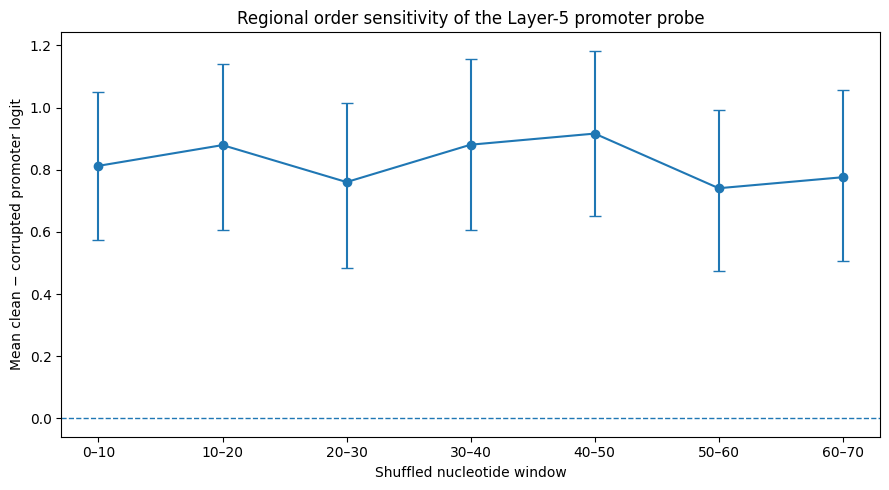

Figure saved to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_behavioral_localization/regional_shuffle_bootstrap_confidence_intervals.png


In [12]:
N_BOOTSTRAPS = 2000
bootstrap_rng = np.random.default_rng(SEED)

window_bootstrap_rows = []

for (window_start, window_end), window_df in regional_results.groupby(
    ["window_start", "window_end"]
):
    # Average repeats within each promoter first.
    per_sequence_effects = (
        window_df
        .groupby("sequence_index")["logit_drop"]
        .mean()
        .to_numpy()
    )

    bootstrap_means = []

    for _ in range(N_BOOTSTRAPS):
        sampled_effects = bootstrap_rng.choice(
            per_sequence_effects,
            size=len(per_sequence_effects),
            replace=True,
        )

        bootstrap_means.append(
            sampled_effects.mean()
        )

    bootstrap_means = np.asarray(bootstrap_means)

    window_bootstrap_rows.append({
        "window_start": window_start,
        "window_end": window_end,
        "mean_logit_drop": per_sequence_effects.mean(),
        "ci_2.5": np.percentile(bootstrap_means, 2.5),
        "ci_97.5": np.percentile(bootstrap_means, 97.5),
        "standard_error": bootstrap_means.std(ddof=1),
    })

regional_bootstrap_summary = (
    pd.DataFrame(window_bootstrap_rows)
    .sort_values("window_start")
    .reset_index(drop=True)
)

regional_bootstrap_summary["window_label"] = (
    regional_bootstrap_summary["window_start"].astype(str)
    + "–"
    + regional_bootstrap_summary["window_end"].astype(str)
)

display(regional_bootstrap_summary)

# Plot means with 95% bootstrap confidence intervals.
plt.figure(figsize=(9, 5))

means = regional_bootstrap_summary["mean_logit_drop"].to_numpy()

lower_errors = (
    means
    - regional_bootstrap_summary["ci_2.5"].to_numpy()
)

upper_errors = (
    regional_bootstrap_summary["ci_97.5"].to_numpy()
    - means
)

plt.errorbar(
    regional_bootstrap_summary["window_label"],
    means,
    yerr=[lower_errors, upper_errors],
    fmt="o-",
    capsize=4,
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

plt.xlabel("Shuffled nucleotide window")
plt.ylabel("Mean clean − corrupted promoter logit")
plt.title(
    "Regional order sensitivity of the Layer-5 promoter probe"
)

plt.tight_layout()

figure_path = (
    BEHAVIOR_DIR
    / "regional_shuffle_bootstrap_confidence_intervals.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

regional_bootstrap_summary.to_csv(
    BEHAVIOR_DIR
    / "regional_shuffle_bootstrap_summary.csv",
    index=False,
)

print("Figure saved to:", figure_path)

# Cell 13 — Test whether promoter evidence depends on absolute position

Shift sizes: [5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65]
Total shifted sequences: 5200


Extracting Layer-5 representations:   0%|          | 0/163 [00:00<?, ?it/s]

,shift_size,mean_logit_drop,median_logit_drop,std_logit_drop,mean_probability_drop,fraction_positive,mean_shifted_probability
0,5,0.347661,0.133692,3.330679,0.020608,0.5175,0.703275
1,10,0.380443,0.442523,3.601359,0.008915,0.5400,0.714968
2,15,0.561828,0.882393,3.859677,0.024987,0.5700,0.698896
3,20,0.527239,0.634673,4.115775,0.033597,0.5725,0.690285
4,25,0.829234,0.543466,3.988843,0.037865,0.5950,0.686018
5,30,0.777513,0.730783,3.867559,0.035568,0.5875,0.688314
6,35,0.906495,0.734822,4.053384,0.046557,0.5825,0.677326
7,40,0.270011,0.083292,4.064460,0.011023,0.5100,0.712860
8,45,0.359538,0.397552,4.080462,0.008010,0.5375,0.715873
9,50,0.309534,0.116935,4.098339,0.000392,0.5125,0.723490



Mean effect across all nonzero shifts: 0.4754538197983883
Overall fraction with reduced promoter score: 0.5478846153846154


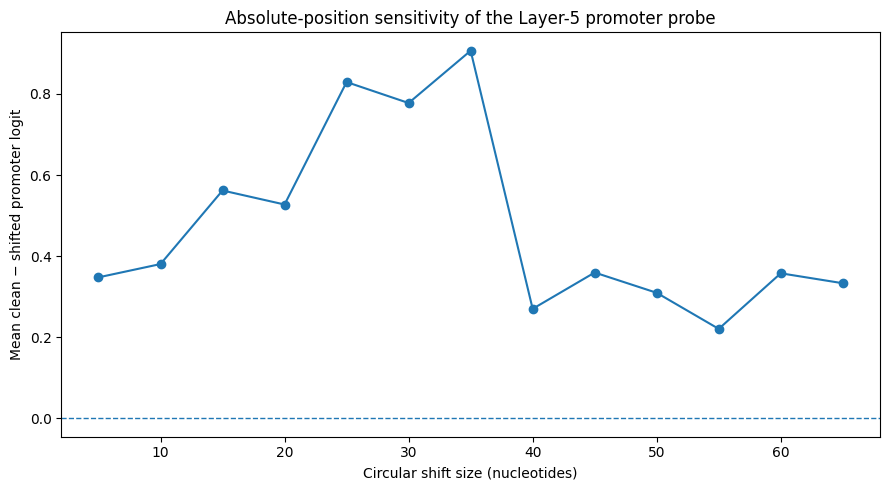

Figure saved to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_behavioral_localization/circular_shift_positional_sensitivity.png


In [13]:
SHIFT_SIZES = list(range(5, SEQUENCE_LENGTH, 5))

def circular_shift(sequence, shift):
    """
    Circularly shift the sequence to the right.

    Preserves:
    - sequence length,
    - exact nucleotide composition,
    - nearly all local sequence content,

    but changes the absolute positions of sequence patterns.
    """
    shift = shift % len(sequence)

    if shift == 0:
        return sequence

    return sequence[-shift:] + sequence[:-shift]


shifted_sequences = []
shift_metadata = []

for shift_size in SHIFT_SIZES:
    for sequence_index, sequence in enumerate(promoter_sequences):
        shifted_sequence = circular_shift(
            sequence,
            shift=shift_size,
        )

        assert len(shifted_sequence) == len(sequence)
        assert Counter(shifted_sequence) == Counter(sequence)

        shifted_sequences.append(shifted_sequence)

        shift_metadata.append({
            "sequence_index": sequence_index,
            "shift_size": shift_size,
        })


print("Shift sizes:", SHIFT_SIZES)
print("Total shifted sequences:", len(shifted_sequences))

(
    shifted_representations,
    shifted_probabilities,
    shifted_logits,
) = score_sequences_with_layer5_probe(
    shifted_sequences,
    batch_size=32,
)

circular_shift_results = pd.DataFrame(shift_metadata)

circular_shift_results["shifted_logit"] = shifted_logits
circular_shift_results["shifted_probability"] = (
    shifted_probabilities
)

circular_shift_results["clean_logit"] = (
    circular_shift_results["sequence_index"]
    .map(clean_logit_lookup)
)

circular_shift_results["clean_probability"] = (
    circular_shift_results["sequence_index"]
    .map(clean_probability_lookup)
)

circular_shift_results["logit_drop"] = (
    circular_shift_results["clean_logit"]
    - circular_shift_results["shifted_logit"]
)

circular_shift_results["probability_drop"] = (
    circular_shift_results["clean_probability"]
    - circular_shift_results["shifted_probability"]
)

circular_shift_summary = (
    circular_shift_results
    .groupby("shift_size")
    .agg(
        mean_logit_drop=("logit_drop", "mean"),
        median_logit_drop=("logit_drop", "median"),
        std_logit_drop=("logit_drop", "std"),
        mean_probability_drop=("probability_drop", "mean"),
        fraction_positive=("logit_drop", lambda x: np.mean(x > 0)),
        mean_shifted_probability=("shifted_probability", "mean"),
    )
    .reset_index()
)

display(circular_shift_summary)

print(
    "\nMean effect across all nonzero shifts:",
    circular_shift_results["logit_drop"].mean(),
)

print(
    "Overall fraction with reduced promoter score:",
    np.mean(circular_shift_results["logit_drop"] > 0),
)

# Plot positional sensitivity by shift size.
plt.figure(figsize=(9, 5))

plt.plot(
    circular_shift_summary["shift_size"],
    circular_shift_summary["mean_logit_drop"],
    marker="o",
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

plt.xlabel("Circular shift size (nucleotides)")
plt.ylabel("Mean clean − shifted promoter logit")
plt.title(
    "Absolute-position sensitivity of the Layer-5 promoter probe"
)

plt.tight_layout()

shift_figure_path = (
    BEHAVIOR_DIR
    / "circular_shift_positional_sensitivity.png"
)

plt.savefig(
    shift_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

circular_shift_results.to_csv(
    BEHAVIOR_DIR / "circular_shift_all_results.csv",
    index=False,
)

circular_shift_summary.to_csv(
    BEHAVIOR_DIR / "circular_shift_summary.csv",
    index=False,
)

print("Figure saved to:", shift_figure_path)

# Cell 14 — Set up exact dinucleotide-preserving sequence shuffling

In [14]:
!pip install -q ushuffle

  Preparing metadata (setup.py) ... done


# Cell 14B — Define and validate dinucleotide-preserving corruption

In [15]:
from collections import Counter
from ushuffle import shuffle as ushuffle_sequence
from ushuffle import set_seed as ushuffle_set_seed


def kmer_counts(sequence, k):
    return Counter(
        sequence[index:index + k]
        for index in range(len(sequence) - k + 1)
    )


def dinucleotide_shuffle(sequence, seed):
    """
    Generate a reproducible shuffled sequence preserving
    exact dinucleotide counts.
    """
    ushuffle_set_seed(seed)

    shuffled = ushuffle_sequence(
        sequence.encode("ascii"),
        2,
    )

    return shuffled.decode("ascii")


# Smoke test on several promoter sequences.
for sequence_index, sequence in enumerate(promoter_sequences[:20]):
    shuffled = dinucleotide_shuffle(
        sequence,
        seed=SEED + sequence_index,
    )

    assert len(shuffled) == len(sequence)
    assert Counter(shuffled) == Counter(sequence)
    assert kmer_counts(shuffled, 2) == kmer_counts(sequence, 2)

print("Dinucleotide-preserving shuffle validation passed.")

print("\nExample clean sequence:")
print(promoter_sequences[0])

print("\nExample dinucleotide-preserving shuffle:")
print(
    dinucleotide_shuffle(
        promoter_sequences[0],
        seed=SEED,
    )
)

Dinucleotide-preserving shuffle validation passed.

Example clean sequence:
GGTAGATAAGAGAAACCGCGATCGGAGTACGGCGCGTGCGCAGATCAGGGATCGCGATTGCGAATCCTCC

Example dinucleotide-preserving shuffle:
GCGTCGGCCAAAAGCTACGATTGAACGCGGATCGGAGGGTCGCGTAGAGATATCGCAGAGATGCCCGATC


# Cell 15 — Measure sensitivity beyond dinucleotide composition

In [16]:
N_DINUC_REPEATS = 10

dinuc_sequences = []
dinuc_sequence_indices = []
dinuc_repeat_ids = []

for repeat_id in range(N_DINUC_REPEATS):
    for sequence_index, sequence in enumerate(promoter_sequences):
        shuffled_sequence = dinucleotide_shuffle(
            sequence,
            seed=SEED
            + repeat_id * len(promoter_sequences)
            + sequence_index,
        )

        dinuc_sequences.append(shuffled_sequence)
        dinuc_sequence_indices.append(sequence_index)
        dinuc_repeat_ids.append(repeat_id)

print("Total dinucleotide-preserving corruptions:", len(dinuc_sequences))

(
    dinuc_representations,
    dinuc_probabilities,
    dinuc_logits,
) = score_sequences_with_layer5_probe(
    dinuc_sequences,
    batch_size=32,
)

dinuc_results = pd.DataFrame({
    "sequence_index": dinuc_sequence_indices,
    "repeat_id": dinuc_repeat_ids,
    "dinuc_logit": dinuc_logits,
    "dinuc_probability": dinuc_probabilities,
})

dinuc_results["clean_logit"] = (
    dinuc_results["sequence_index"]
    .map(clean_logit_lookup)
)

dinuc_results["clean_probability"] = (
    dinuc_results["sequence_index"]
    .map(clean_probability_lookup)
)

dinuc_results["logit_drop"] = (
    dinuc_results["clean_logit"]
    - dinuc_results["dinuc_logit"]
)

dinuc_results["probability_drop"] = (
    dinuc_results["clean_probability"]
    - dinuc_results["dinuc_probability"]
)

per_promoter_dinuc_summary = (
    dinuc_results
    .groupby("sequence_index")
    .agg(
        clean_logit=("clean_logit", "first"),
        mean_dinuc_logit=("dinuc_logit", "mean"),
        std_dinuc_logit=("dinuc_logit", "std"),
        mean_logit_drop=("logit_drop", "mean"),
        clean_probability=("clean_probability", "first"),
        mean_dinuc_probability=("dinuc_probability", "mean"),
        mean_probability_drop=("probability_drop", "mean"),
    )
    .reset_index()
)

display(per_promoter_dinuc_summary.describe())

print(
    "\nMean dinucleotide-preserving logit drop:",
    per_promoter_dinuc_summary["mean_logit_drop"].mean(),
)

print(
    "Median dinucleotide-preserving logit drop:",
    per_promoter_dinuc_summary["mean_logit_drop"].median(),
)

print(
    "Fraction with positive mean drop:",
    np.mean(
        per_promoter_dinuc_summary["mean_logit_drop"] > 0
    ),
)

print(
    "Mean dinucleotide-shuffled promoter probability:",
    per_promoter_dinuc_summary[
        "mean_dinuc_probability"
    ].mean(),
)

dinuc_results.to_csv(
    BEHAVIOR_DIR / "dinucleotide_shuffle_all_repeats.csv",
    index=False,
)

per_promoter_dinuc_summary.to_csv(
    BEHAVIOR_DIR / "dinucleotide_shuffle_per_promoter_summary.csv",
    index=False,
)

print("\nDinucleotide results saved.")

Total dinucleotide-preserving corruptions: 4000


Extracting Layer-5 representations:   0%|          | 0/125 [00:00<?, ?it/s]

,sequence_index,clean_logit,mean_dinuc_logit,std_dinuc_logit,mean_logit_drop,clean_probability,mean_dinuc_probability,mean_probability_drop
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000
mean,199.500000,3.826984,1.998178,3.816251,1.828806,0.723883,0.615710,0.108173
std,115.614301,6.468729,4.407557,1.030148,4.700867,0.373312,0.277024,0.318059
min,0.000000,-12.932936,-9.289409,1.661685,-16.109580,0.000002,0.000592,-0.820327
25%,99.750000,-0.290591,-0.964928,3.120082,-1.098725,0.427865,0.400290,-0.056102
50%,199.500000,3.448689,1.363212,3.686136,1.842956,0.969179,0.637371,0.085517
75%,299.250000,6.785130,4.444500,4.389795,4.594468,0.998871,0.863329,0.326775
max,399.000000,34.296556,17.711901,8.256678,19.542668,1.000000,0.999997,0.858340



Mean dinucleotide-preserving logit drop: 1.8288059766511362
Median dinucleotide-preserving logit drop: 1.8429561350881907
Fraction with positive mean drop: 0.665
Mean dinucleotide-shuffled promoter probability: 0.6157099104136736

Dinucleotide results saved.


# Cell 16 — Compare mononucleotide and dinucleotide corruption effects

,mononucleotide_logit_drop,dinucleotide_logit_drop,drop_difference
count,400.000000,400.000000,400.000000
mean,4.706492,1.828806,2.877686
std,5.401942,4.700867,3.429234
min,-10.567218,-16.109580,-9.233561
25%,1.139926,-1.098725,0.688546
50%,4.809638,1.842956,2.749939
75%,8.134291,4.594468,4.991499
max,25.642141,19.542668,15.450346



Mean mononucleotide-shuffle drop: 4.706492095632609
Mean dinucleotide-shuffle drop: 1.8288059766511362
Mean paired difference: 2.8776861189814738
Dinucleotide effect as fraction of mononucleotide effect: 0.38857092277880956

Wilcoxon statistic: 71350.0
One-sided p-value: 7.175398492134316e-42

95% bootstrap CI for mean paired difference: [2.5474627  3.21526634]


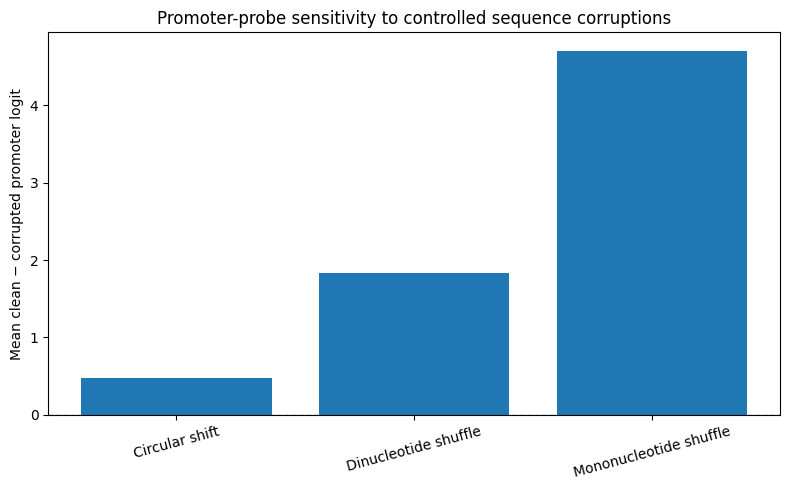

Figure saved to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_behavioral_localization/corruption_effect_comparison.png


,condition,mean_promoter_probability,mean_logit_drop,fraction_score_reduced,interpretation
0,Clean promoters,0.723883,0.000000,NaN,Uncorrupted reference
1,Circular shift,0.704677,0.475454,0.547885,Mostly preserves promoter evidence; original a...
2,Single 10-nt regional shuffle,NaN,0.823470,0.597786,Order sensitivity is distributed; no single 10...
3,Dinucleotide-preserving shuffle,0.615710,1.828806,0.665000,Longer motifs or higher-order organization con...
4,Mononucleotide-preserving shuffle,0.421480,4.706492,0.810000,Strong dependence on nucleotide order beyond G...



Promoters with strongest loss after full shuffling:


,sequence_index,sequence,clean_logit,clean_probability,mono_logit_drop,dinuc_logit_drop,mono_minus_dinuc
296,296,TCCCCCGCTCCGGGCTGCAGCGGCGCAGGCGCCGGGCCGAGCCGAG...,34.296556,1.000000,25.642141,19.542668,6.099472
362,362,GGCCGGCTCTGCGCCCCGCGGCTCTCGCTCCCGGCCGGGGTTCCTG...,28.975672,1.000000,19.800927,16.627784,3.173143
74,74,CCTGGGATTGGGACACACTTTCTGGGCACTGCTGGCCAGTCCCAAA...,12.896263,0.999997,19.695766,11.737207,7.958559
89,89,AGAACAAAGAGCCTCCCCGCGCTCCCGCTCTCCGCTCCTCTCCCCG...,22.184286,1.000000,18.359111,9.214972,9.144139
388,388,GCCGCCCCTCCTTTCCCTTTCCGCTCTCTCCGCCTCCGGAAGCGCG...,22.002731,1.000000,17.920230,12.730721,5.189509
80,80,GGAAGCCTTGCCCCAACTCAGGAGTTTAGCCCCAGACCTTCTGTCC...,9.990122,0.999954,17.796133,5.642100,12.154033
82,82,ATACAGCTCAAAATAACTTGGGACCTGTGAGCTGACAAATGCTCTG...,9.493075,0.999925,17.410944,8.637347,8.773597
324,324,TGCCGGCTCGGTGGCGCGGCCGCGCGTGCTCCCGCCCCTCGCCGCC...,29.489670,1.000000,17.138092,16.243928,0.894164
265,265,GGAGGAGGAAGCCAAGAGGGGAGTTGGTGAGTCAGAGGAGAAAAGC...,17.087557,1.000000,16.585124,13.634158,2.950967
115,115,CGCCCTCCCCACCGCCCTCTGCGGGAGCCGGGCAGCTGCAGCGGAG...,23.957943,1.000000,16.491464,14.861795,1.629670



Promoters most resistant to full shuffling:


,sequence_index,sequence,clean_logit,clean_probability,mono_logit_drop,dinuc_logit_drop,mono_minus_dinuc
87,87,CGGACGTGAAGCATCTACAAAGGAGGAATAGTCAAAGCAGCAGCGG...,-8.696098,0.000167,-10.567218,-10.709728,0.142510
264,264,TGCAGAGTTGTATGACCAGGTGGAAAGTTAAACAGACGCTCCACTC...,-12.932936,0.000002,-10.126217,-10.441462,0.315245
101,101,AATTTCAGATAGAGTACAATGAATCTATGAAGGCCTATCATAATTC...,-12.612533,0.000003,-7.661079,-6.572786,-1.088293
347,347,TGTCCGCCATGGGGCTCGCCGCCTGCCGCGCCTGACCCGGCCGCCG...,0.898915,0.710727,-7.644349,1.589212,-9.233561
94,94,GGCGGGGAGGGGGTTAACGCGCGCGGCCTCTATGATAATGAGCTGC...,-6.941602,0.000966,-6.820409,-2.370528,-4.449880
332,332,CGTAGCAGGCGGGGCACAGAGGAGGGAACGCTTGTGTCTAACTGAT...,-9.212264,0.000100,-6.744462,-8.726866,1.982403
60,60,AGGCCGTGGCCTGGGCCCAGGTCCCCGGAGGAGGCCGCGCCGCCCG...,6.490801,0.998485,-5.831239,-0.530511,-5.300729
136,136,CGGCGCCCTCGGGTCGGCTGAGCGCTAAGCGCCAGTGTACAGCGGC...,-1.360239,0.204202,-5.794561,-5.154268,-0.640293
149,149,GGCGCGGGGGCTGTAGGGAGGGGGACCAGTGGCAGAGGGACCTTAG...,-7.038883,0.000876,-5.338303,-6.510360,1.172057
178,178,TAATCCTGGCCGTGTGTGCGCGCGTGGGGCTCCATTCCGCGGTGCT...,-0.697220,0.332429,-5.268934,-4.263318,-1.005616



Promoters most protected by preserving dinucleotides:


,sequence_index,sequence,clean_logit,clean_probability,mono_logit_drop,dinuc_logit_drop,mono_minus_dinuc
378,378,GGCGGCGGCAGCGGCGGCTAGAAGCGGCAGCCCAGAGCCCTCTCGC...,8.979748,0.999874,6.718193,-8.732153,15.450346
226,226,CACACACACACACACACACACACACACACACACACACACGCCTTTG...,-0.545217,0.366975,-1.569822,-16.109580,14.539758
254,254,CACGCTCGTTCGCTCGCTCGCCGGCTCCTCCTCACTCGCCCGCCCG...,16.049870,1.000000,14.540397,0.870837,13.669561
80,80,GGAAGCCTTGCCCCAACTCAGGAGTTTAGCCCCAGACCTTCTGTCC...,9.990122,0.999954,17.796133,5.642100,12.154033
315,315,TCGGCTCCTCGCCTTCCCCCTCCCGTCCGCCTTCTCCCCTCCCTCC...,10.871462,0.999981,12.605138,0.510653,12.094485
86,86,TGCATCCCAGCCCCCTGATCCAGCCAGCTGTCTGACTGTGAGTCAG...,1.942995,0.874681,7.601732,-2.282488,9.884220
396,396,CTCTTAGCCTCTTCCTCCTGCTTGCCACCTCTCAGTCACAAGACGG...,11.383169,0.999989,15.259429,5.596635,9.662794
158,158,TGCATTCTGCTCTTTTTGAGAGCACAGCTTCTCAGATGTGCTCCTT...,6.318531,0.998201,10.861951,1.275834,9.586117
41,41,AAATGGGAGTCTCCCTGCACAAGCTTCTTTTGTCTGCTGCCTTGTG...,5.432572,0.995647,7.971599,-1.488042,9.459640
379,379,GTCACCGGCTTGGCGAGGGTCTCCTCTGACCCACTTAGCCTTGCCA...,2.384009,0.915600,8.378045,-1.034675,9.412720



Final summary saved to:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_behavioral_localization/behavioral_localization_summary.csv

Conclusions saved to:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_behavioral_localization/NOTEBOOK_2_CONCLUSIONS.md

Notebook 2 complete.


In [17]:
from scipy.stats import wilcoxon

comparison_df = pd.DataFrame({
    "sequence_index": per_promoter_shuffle_summary["sequence_index"],
    "clean_logit": per_promoter_shuffle_summary["clean_logit"],
    "mononucleotide_logit_drop": (
        per_promoter_shuffle_summary["mean_logit_drop"]
    ),
    "dinucleotide_logit_drop": (
        per_promoter_dinuc_summary["mean_logit_drop"]
    ),
})

comparison_df["drop_difference"] = (
    comparison_df["mononucleotide_logit_drop"]
    - comparison_df["dinucleotide_logit_drop"]
)

comparison_df["fraction_of_mono_effect_remaining"] = (
    comparison_df["dinucleotide_logit_drop"]
    / comparison_df["mononucleotide_logit_drop"].replace(0, np.nan)
)

display(
    comparison_df[
        [
            "mononucleotide_logit_drop",
            "dinucleotide_logit_drop",
            "drop_difference",
        ]
    ].describe()
)

# Paired non-parametric test.
wilcoxon_result = wilcoxon(
    comparison_df["mononucleotide_logit_drop"],
    comparison_df["dinucleotide_logit_drop"],
    alternative="greater",
)

print(
    "\nMean mononucleotide-shuffle drop:",
    comparison_df["mononucleotide_logit_drop"].mean(),
)

print(
    "Mean dinucleotide-shuffle drop:",
    comparison_df["dinucleotide_logit_drop"].mean(),
)

print(
    "Mean paired difference:",
    comparison_df["drop_difference"].mean(),
)

print(
    "Dinucleotide effect as fraction of mononucleotide effect:",
    comparison_df["dinucleotide_logit_drop"].mean()
    / comparison_df["mononucleotide_logit_drop"].mean(),
)

print(
    "\nWilcoxon statistic:",
    wilcoxon_result.statistic,
)

print(
    "One-sided p-value:",
    wilcoxon_result.pvalue,
)

# Bootstrap the mean paired difference.
N_BOOTSTRAPS = 5000
rng = np.random.default_rng(SEED)

paired_differences = comparison_df["drop_difference"].to_numpy()

bootstrap_differences = np.empty(N_BOOTSTRAPS)

for bootstrap_index in range(N_BOOTSTRAPS):
    sampled = rng.choice(
        paired_differences,
        size=len(paired_differences),
        replace=True,
    )

    bootstrap_differences[bootstrap_index] = sampled.mean()

difference_ci = np.percentile(
    bootstrap_differences,
    [2.5, 97.5],
)

print(
    "\n95% bootstrap CI for mean paired difference:",
    difference_ci,
)

# Summary figure.
condition_names = [
    "Circular shift",
    "Dinucleotide shuffle",
    "Mononucleotide shuffle",
]

condition_means = [
    circular_shift_results["logit_drop"].mean(),
    comparison_df["dinucleotide_logit_drop"].mean(),
    comparison_df["mononucleotide_logit_drop"].mean(),
]

plt.figure(figsize=(8, 5))

plt.bar(
    condition_names,
    condition_means,
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

plt.ylabel("Mean clean − corrupted promoter logit")
plt.title("Promoter-probe sensitivity to controlled sequence corruptions")
plt.xticks(rotation=15)
plt.tight_layout()

comparison_figure_path = (
    BEHAVIOR_DIR
    / "corruption_effect_comparison.png"
)

plt.savefig(
    comparison_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

comparison_df.to_csv(
    BEHAVIOR_DIR / "mono_vs_dinucleotide_comparison.csv",
    index=False,
)

print("Figure saved to:", comparison_figure_path)

# Cell 17 — Final behavioral-localization summary and saved conclusions

# Mean regional effect across the seven 10-nt windows.
mean_regional_logit_drop = (
    regional_window_summary["mean_logit_drop"].mean()
)

summary_table = pd.DataFrame([
    {
        "condition": "Clean promoters",
        "mean_promoter_probability": (
            promoter_clean_probabilities.mean()
        ),
        "mean_logit_drop": 0.0,
        "fraction_score_reduced": np.nan,
        "interpretation": "Uncorrupted reference",
    },
    {
        "condition": "Circular shift",
        "mean_promoter_probability": (
            circular_shift_results["shifted_probability"].mean()
        ),
        "mean_logit_drop": (
            circular_shift_results["logit_drop"].mean()
        ),
        "fraction_score_reduced": (
            circular_shift_results["logit_drop"] > 0
        ).mean(),
        "interpretation": (
            "Mostly preserves promoter evidence; "
            "original alignment is a weaker dependency"
        ),
    },
    {
        "condition": "Single 10-nt regional shuffle",
        "mean_promoter_probability": np.nan,
        "mean_logit_drop": mean_regional_logit_drop,
        "fraction_score_reduced": (
            regional_results["logit_drop"] > 0
        ).mean(),
        "interpretation": (
            "Order sensitivity is distributed; "
            "no single 10-nt window dominates"
        ),
    },
    {
        "condition": "Dinucleotide-preserving shuffle",
        "mean_promoter_probability": (
            per_promoter_dinuc_summary[
                "mean_dinuc_probability"
            ].mean()
        ),
        "mean_logit_drop": (
            per_promoter_dinuc_summary[
                "mean_logit_drop"
            ].mean()
        ),
        "fraction_score_reduced": (
            per_promoter_dinuc_summary[
                "mean_logit_drop"
            ] > 0
        ).mean(),
        "interpretation": (
            "Longer motifs or higher-order organization "
            "contribute beyond dinucleotide statistics"
        ),
    },
    {
        "condition": "Mononucleotide-preserving shuffle",
        "mean_promoter_probability": (
            per_promoter_shuffle_summary[
                "mean_shuffled_probability"
            ].mean()
        ),
        "mean_logit_drop": (
            per_promoter_shuffle_summary[
                "mean_logit_drop"
            ].mean()
        ),
        "fraction_score_reduced": (
            per_promoter_shuffle_summary[
                "mean_logit_drop"
            ] > 0
        ).mean(),
        "interpretation": (
            "Strong dependence on nucleotide order "
            "beyond GC and base composition"
        ),
    },
])

display(summary_table)

# Identify heterogeneous promoter examples.
heterogeneity_df = pd.DataFrame({
    "sequence_index": np.arange(len(promoter_sequences)),
    "sequence": promoter_sequences,
    "clean_logit": promoter_clean_logits,
    "clean_probability": promoter_clean_probabilities,
    "mono_logit_drop": (
        per_promoter_shuffle_summary[
            "mean_logit_drop"
        ].to_numpy()
    ),
    "dinuc_logit_drop": (
        per_promoter_dinuc_summary[
            "mean_logit_drop"
        ].to_numpy()
    ),
})

heterogeneity_df["mono_minus_dinuc"] = (
    heterogeneity_df["mono_logit_drop"]
    - heterogeneity_df["dinuc_logit_drop"]
)

strongest_loss_examples = (
    heterogeneity_df
    .sort_values("mono_logit_drop", ascending=False)
    .head(10)
)

most_resistant_examples = (
    heterogeneity_df
    .sort_values("mono_logit_drop", ascending=True)
    .head(10)
)

largest_dinucleotide_protection = (
    heterogeneity_df
    .sort_values("mono_minus_dinuc", ascending=False)
    .head(10)
)

print("\nPromoters with strongest loss after full shuffling:")
display(strongest_loss_examples)

print("\nPromoters most resistant to full shuffling:")
display(most_resistant_examples)

print("\nPromoters most protected by preserving dinucleotides:")
display(largest_dinucleotide_protection)

# Save final outputs.
summary_table.to_csv(
    BEHAVIOR_DIR / "behavioral_localization_summary.csv",
    index=False,
)

heterogeneity_df.to_csv(
    BEHAVIOR_DIR / "promoter_heterogeneity_results.csv",
    index=False,
)

strongest_loss_examples.to_csv(
    BEHAVIOR_DIR / "strongest_shuffle_loss_examples.csv",
    index=False,
)

most_resistant_examples.to_csv(
    BEHAVIOR_DIR / "shuffle_resistant_examples.csv",
    index=False,
)

largest_dinucleotide_protection.to_csv(
    BEHAVIOR_DIR
    / "largest_dinucleotide_protection_examples.csv",
    index=False,
)

final_conclusions = """
# Notebook 2: Promoter Behavioral Localization

## Experimental target

A logistic diagnostic probe trained on mean-pooled Layer-5
representations from baseline, non-fine-tuned DNABERT-2.

This is a representation-level readout, not a native DNABERT-2
promoter-classification output.

## Main findings

1. Clean test performance reproduced the original pilot:
   balanced accuracy = 0.735 and ROC-AUC = 0.811.

2. Exact mononucleotide-preserving shuffling caused a mean promoter-logit
   drop of 4.706. Eighty-one percent of promoter sequences showed a
   positive mean drop across repeated shuffles.

3. Because exact A/C/G/T counts were preserved, the full-shuffle effect
   cannot be explained by GC content or mononucleotide composition alone.

4. Exact dinucleotide-preserving shuffling caused a smaller but meaningful
   mean logit drop of 1.829. Therefore, dinucleotide statistics preserve
   substantial promoter-associated information, but do not explain all of it.

5. The paired difference between mononucleotide- and dinucleotide-preserving
   shuffle effects was 2.878 logits, with a bootstrap 95% confidence interval
   of [2.547, 3.215] and a one-sided Wilcoxon p-value of approximately
   7.18e-42.

6. The dinucleotide-preserving effect was approximately 38.9% of the
   mononucleotide-preserving shuffle effect. This residual is consistent
   with sensitivity to longer motifs or higher-order sequence organization.

7. Circular shifts produced a much smaller mean logit drop of 0.475.
   Thus, promoter-associated evidence depended more strongly on retained
   local sequence structure than on the original alignment within the
   70-nucleotide input.

8. Shuffling individual 10-nucleotide windows produced positive effects
   across all regions, with heavily overlapping bootstrap confidence
   intervals. No single 10-nucleotide region dominated under this test.

## Supported conclusion

Baseline DNABERT-2 Layer-5 representations contain promoter-associated
information that depends strongly on nucleotide order. Much of this
dependence is captured by dinucleotide statistics, while a significant
residual depends on longer-range motifs or higher-order sequence structure.
The effect appears distributed across the input rather than sharply
localized to one 10-nucleotide region.

## Limitations

- The measured output is a trained linear diagnostic probe, not a native
  promoter classifier.
- Corruption sensitivity does not identify specific biological motifs.
- Circular shifting is not a pure absolute-position intervention because
  it changes sequence boundaries and tokenizer segmentation.
- Regional shuffling may disrupt multiple overlapping motifs and therefore
  cannot by itself establish causal biological localization.
- Component-level and activation-level interventions are needed before
  making mechanistic circuit claims.

## Next stage

Use these clean-versus-corrupt conditions as behavioral targets for
component localization across DNABERT-2 layers, attention heads, and MLPs.
"""

conclusion_path = (
    BEHAVIOR_DIR / "NOTEBOOK_2_CONCLUSIONS.md"
)

with open(conclusion_path, "w") as file:
    file.write(final_conclusions.strip())

print("\nFinal summary saved to:")
print(BEHAVIOR_DIR / "behavioral_localization_summary.csv")

print("\nConclusions saved to:")
print(conclusion_path)

print("\nNotebook 2 complete.")